# Análisis de los datos

Este notebook reúne los análisis que se le hicieron a los datos: cómo se comporta el precio de
bolsa, por qué se trabaja con su logaritmo y con su cambio a una semana, qué ciclos tiene y qué
variables se mueven con él. Cómo se limpiaron y organizaron los datos está en
`0_datos_limpieza_y_estructura.ipynb`.

Las figuras que describen el precio usan toda la serie, del 1 de marzo de 2015 al 6 de octubre de
2026. Los análisis que sirvieron para tomar decisiones de los modelos usan solo 2015-2019 o
2015-2022, como el resto de la tesis, para no mirar el periodo de prueba.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf

# pandas 2.3 con numpy 2.5 avisa por una unidad interna de las fechas; no cambia nada
warnings.filterwarnings("ignore", message="The 'generic' unit for NumPy timedelta")
# la KPSS solo da valores p entre 0,01 y 0,10, y avisa cuando el estadístico se sale de ese rango
warnings.filterwarnings("ignore", category=InterpolationWarning)

RAIZ = Path("datos")
PANELES = RAIZ / "paneles"

AZUL = "#2a78d6"
AZUL_CLARO = "#86b6ef"
AZUL_OSCURO = "#0d366b"
ROJO = "#e34948"
GRIS = "#52514e"
GRIS_MEDIO = "#898781"
GRIS_CLARO = "#c3c2b7"
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
DIAS = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white", "axes.grid": True,
                     "grid.color": "#e5e4df", "axes.edgecolor": "#c3c2b7", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlelocation": "left", "axes.titlesize": 11,
                     "legend.frameon": False})
pd.set_option("display.precision", 3)


def pct(x):
    # una diferencia en logaritmo, llevada a porcentaje
    return 100 * (np.exp(x) - 1)

In [2]:
horario = pd.read_csv(PANELES / "panel_horario_modelo.csv.gz", parse_dates=["fecha"],
                      usecols=["fecha", "hora", "precio", "lp", "es_festivo"])
diario = pd.read_csv(PANELES / "panel_diario.csv", parse_dates=["fecha"], index_col="fecha")
diario = diario.loc["2015-03-01":"2026-10-06"]

# una fila por día y una columna por hora
PRECIO = horario.pivot(index="fecha", columns="hora", values="precio")
LP = horario.pivot(index="fecha", columns="hora", values="lp")
precio_dia = PRECIO.mean(axis=1)
lp_dia = LP.mean(axis=1)
print(f"{LP.shape[0]:,} días y {LP.shape[1]} horas, del {LP.index.min().date()} al {LP.index.max().date()}")

4,238 días y 24 horas, del 2015-03-01 al 2026-10-06


## 1. El precio de bolsa entre 2015 y 2026

El precio de bolsa es el precio al que se transa la energía en el mercado de corto plazo, y se
fija hora por hora (CREG 055 de 1994). Como la mayor parte de la energía del país es hidráulica,
el precio depende sobre todo del agua. La figura muestra el precio junto con la anomalía de
temperatura del Pacífico en la región Niño 3.4; las líneas punteadas marcan 0,5 °C por encima y por
debajo de lo normal, el umbral que usa NOAA para El Niño y La Niña.

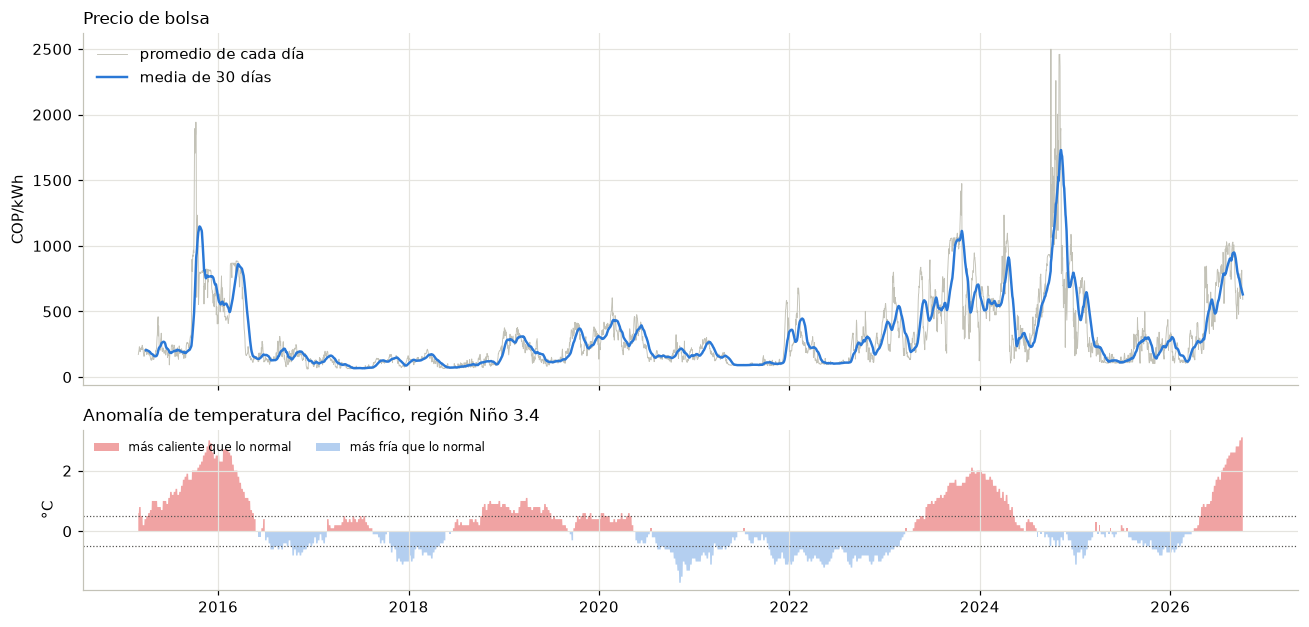

In [3]:
nino = diario["nino34_anom"]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 5.8), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
a1.plot(precio_dia.index, precio_dia, color=GRIS_CLARO, lw=0.6, label="promedio de cada día")
a1.plot(precio_dia.index, precio_dia.rolling(30).mean(), color=AZUL, lw=1.6, label="media de 30 días")
a1.set_ylabel("COP/kWh")
a1.set_title("Precio de bolsa")
a1.legend(loc="upper left")
a2.fill_between(nino.index, nino, 0, where=nino > 0, color=ROJO, alpha=0.5, lw=0, label="más caliente que lo normal")
a2.fill_between(nino.index, nino, 0, where=nino < 0, color=AZUL, alpha=0.35, lw=0, label="más fría que lo normal")
for v in (0.5, -0.5):
    a2.axhline(v, color=GRIS, lw=0.8, ls=":")
a2.set_ylabel("°C")
a2.set_title("Anomalía de temperatura del Pacífico, región Niño 3.4")
a2.legend(loc="upper left", ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

In [4]:
anio = horario["fecha"].dt.year
anual = horario.groupby(anio)["precio"].agg(media="mean", mediana="median", mínimo="min", máximo="max")
por_anio = diario.groupby(diario.index.year)
anual["energía hidráulica (%)"] = 100 * por_anio["gen_hidraulica"].sum() / por_anio["gen_total_sistema"].sum()
anual.rename_axis("año").round(1)

,media,mediana,mínimo,máximo,energía hidráulica (%)
año,,,,,
2015,416.8,231.8,51.1,2821.5,66.4
2016,299.8,175.8,61.1,884.8,71.0
2017,106.1,103.9,60.3,383.5,86.0
2018,116.2,102.7,61.5,555.1,82.2
2019,228.3,220.8,69.9,910.5,77.6
2020,251.1,217.1,71.3,745.5,71.9
2021,150.1,108.0,81.8,592.9,81.8
2022,215.8,200.1,89.1,1035.1,83.7
2023,558.1,499.4,99.4,1595.7,74.2


El precio promedio va de 106 COP/kWh en 2017 a 676 en 2024. Las dos subidas grandes, en 2015-2016
y en 2023-2024, coinciden con la anomalía positiva de Niño 3.4, es decir, con El Niño. En 2015,
2016 y 2024 la energía hidráulica fue de 65% a 71% del total, frente a 86% en 2017. En una hora el
precio llegó a 2.822 COP/kWh en 2015 y a 2.676 en 2024. Tres de los cuatro años del periodo de
prueba (2023, 2024 y 2026) tienen un precio promedio más alto que cualquier año entre 2015 y 2022.

## 2. Distribución del precio y logaritmo

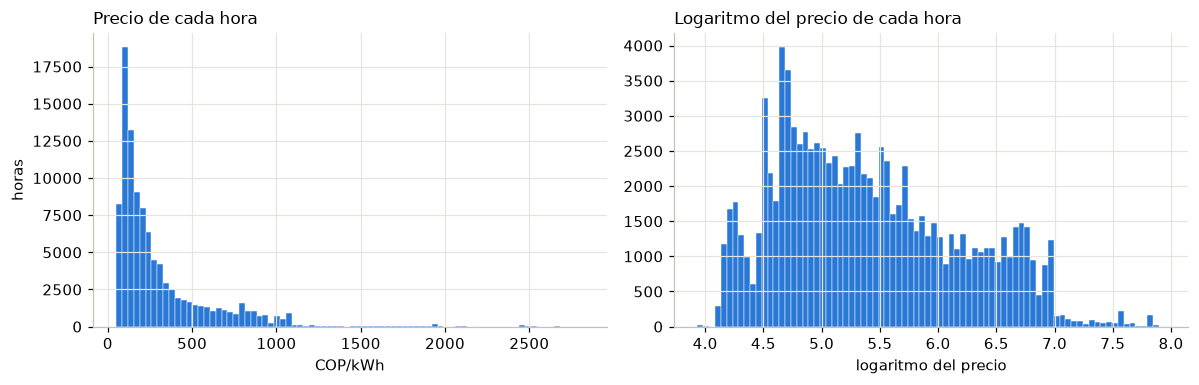

,asimetría,curtosis
precio,2.57,10.13
logaritmo del precio,0.52,-0.55


In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.hist(horario["precio"], bins=80, color=AZUL, edgecolor="white", linewidth=0.3)
a1.set_xlabel("COP/kWh")
a1.set_ylabel("horas")
a1.set_title("Precio de cada hora")
a2.hist(horario["lp"], bins=80, color=AZUL, edgecolor="white", linewidth=0.3)
a2.set_xlabel("logaritmo del precio")
a2.set_title("Logaritmo del precio de cada hora")
plt.tight_layout()
plt.show()

pd.DataFrame({"asimetría": [stats.skew(horario["precio"]), stats.skew(horario["lp"])],
              "curtosis": [stats.kurtosis(horario["precio"]), stats.kurtosis(horario["lp"])]},
             index=["precio", "logaritmo del precio"]).round(2)

El precio tiene una cola larga a la derecha, por unas pocas horas muy caras. Su logaritmo es mucho
más simétrico (asimetría de 0,52 frente a 2,57). Además, el tamaño de los cambios crece con el nivel del precio. La tabla da la
desviación estándar del cambio diario a la misma hora, separando los días según el precio del día
anterior en cinco grupos del mismo tamaño:

In [6]:
nivel = PRECIO.shift(1).stack()
grupo = pd.qcut(nivel, 5)
tabla = pd.DataFrame({"en pesos (COP/kWh)": PRECIO.diff().stack(), "en logaritmo": LP.diff().stack()})
tabla = tabla.groupby(grupo, observed=True).std()
tabla.index = [f"{g.left:.0f} a {g.right:.0f}" for g in tabla.index]
tabla.rename_axis("precio del día anterior (COP/kWh)").round(3)

,en pesos (COP/kWh),en logaritmo
precio del día anterior (COP/kWh),,
51 a 108,30.053,0.192
108 a 156,45.166,0.232
156 a 246,50.881,0.224
246 a 462,81.564,0.243
462 a 2822,192.034,0.244


En pesos, el cambio típico es seis veces más grande cuando el precio está alto que cuando está
bajo. En logaritmo cambia mucho menos, de 0,19 a 0,24, porque el logaritmo mide cambios relativos: subir de 100 a 110 y
de 1.000 a 1.100 es lo mismo. Por eso los tres modelos trabajan con el logaritmo del precio y
pronostican su cambio (Galli, sección 11; Uniejewski et al., 2018).

## 3. Ciclos del precio: hora, día de la semana y mes

El precio de la electricidad tiene ciclos en varias escalas (Weron, 2014). Para verlos sin que pese
el nivel de cada año, cada ciclo se mide frente a una referencia móvil: la hora, frente al promedio
de su día; el día de la semana, frente a la media de los 7 días centrada en él, y el mes, frente a
la media de los 365 días centrada en él. Las diferencias se calculan en logaritmo y se pasan a
porcentaje. En la figura de la hora también está la demanda, medida igual.

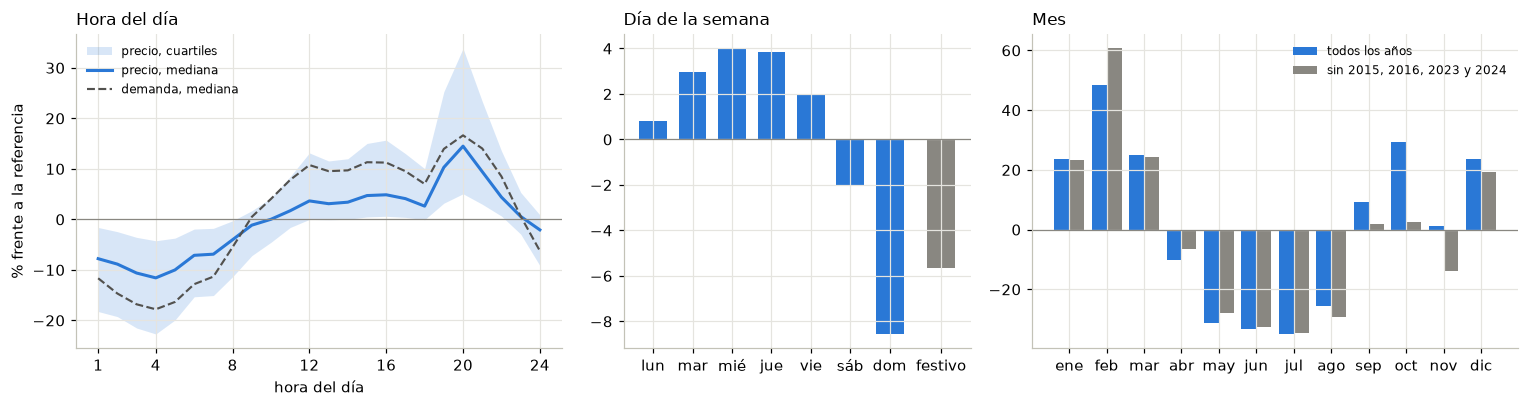

In [7]:
# hora frente al promedio de su día, para el precio y para la demanda
perfil = pct(LP.sub(lp_dia, axis=0).quantile([0.25, 0.5, 0.75])).T
demanda = pd.read_csv(PANELES / "panel_lstm_bloques.csv.gz", parse_dates=["fecha"],
                      usecols=["fecha", "hora", "demanda"])
demanda = demanda[demanda["fecha"].between("2015-03-01", "2026-10-06")].pivot(index="fecha", columns="hora", values="demanda")
perfil_demanda = pct(demanda.sub(demanda.mean(axis=1), axis=0).median())

# día de la semana frente a la media de 7 días; los festivos aparte
semana = lp_dia - lp_dia.rolling(7, center=True).mean()
festivo = horario.groupby("fecha")["es_festivo"].first().astype(bool)
dia = pd.Series(lp_dia.index.dayofweek, index=lp_dia.index)
por_dia = pct(semana[~festivo].groupby(dia[~festivo]).mean())
festivo_entre_semana = pct(semana[festivo & (dia < 5)].mean())

# mes frente a la media de 365 días, con todos los años y sin los de El Niño fuerte
anual_movil = lp_dia - lp_dia.rolling(365, center=True, min_periods=300).mean()
nino_fuerte = anual_movil.index.year.isin([2015, 2016, 2023, 2024])
por_mes = pd.DataFrame({"todos los años": anual_movil.groupby(anual_movil.index.month).median(),
                        "sin 2015, 2016, 2023 y 2024": anual_movil[~nino_fuerte].groupby(anual_movil.index[~nino_fuerte].month).median()})
por_mes = pct(por_mes)

fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.4, 1, 1.4]})
ax = ejes[0]
ax.fill_between(perfil.index, perfil[0.25], perfil[0.75], color=AZUL, alpha=0.18, lw=0, label="precio, cuartiles")
ax.plot(perfil.index, perfil[0.5], color=AZUL, lw=2, label="precio, mediana")
ax.plot(perfil_demanda.index, perfil_demanda, color=GRIS, lw=1.4, ls="--", label="demanda, mediana")
ax.axhline(0, color=GRIS_MEDIO, lw=0.8)
ax.set_xticks([1, 4, 8, 12, 16, 20, 24])
ax.set_xlabel("hora del día")
ax.set_ylabel("% frente a la referencia")
ax.set_title("Hora del día")
ax.legend(fontsize=8)
ax = ejes[1]
ax.bar(range(7), por_dia, color=AZUL, width=0.7)
ax.bar(7.3, festivo_entre_semana, color=GRIS_MEDIO, width=0.7)
ax.axhline(0, color=GRIS_MEDIO, lw=0.8)
ax.set_xticks(list(range(7)) + [7.3], DIAS + ["festivo"])
ax.set_title("Día de la semana")
ax = ejes[2]
x = np.arange(12)
ax.bar(x - 0.2, por_mes["todos los años"], width=0.4, color=AZUL, label="todos los años")
ax.bar(x + 0.2, por_mes["sin 2015, 2016, 2023 y 2024"], width=0.4, color=GRIS_MEDIO, label="sin 2015, 2016, 2023 y 2024")
ax.axhline(0, color=GRIS_MEDIO, lw=0.8)
ax.set_xticks(x, MESES)
ax.set_title("Mes")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [8]:
print(f"hora más cara: {perfil[0.5].idxmax()} ({perfil[0.5].max():+.1f}%), "
      f"hora más barata: {perfil[0.5].idxmin()} ({perfil[0.5].min():+.1f}%)")
print(f"hora de más demanda: {perfil_demanda.idxmax()} ({perfil_demanda.max():+.1f}%)")
print("día de la semana (%):", por_dia.round(1).set_axis(DIAS).to_dict())
print(f"festivo entre semana: {festivo_entre_semana:+.1f}%")
por_mes.set_axis(MESES).round(1).T

hora más cara: 20 (+14.5%), hora más barata: 4 (-11.6%)
hora de más demanda: 20 (+16.6%)
día de la semana (%): {'lun': 0.8, 'mar': 3.0, 'mié': 4.0, 'jue': 3.8, 'vie': 2.0, 'sáb': -2.0, 'dom': -8.6}
festivo entre semana: -5.7%


,ene,feb,mar,abr,may,jun,jul,ago,sep,oct,nov,dic
todos los años,23.7,48.6,25.0,-10.2,-31.3,-33.2,-34.9,-25.5,9.3,29.2,1.2,23.8
"sin 2015, 2016, 2023 y 2024",23.5,60.7,24.2,-6.5,-28.1,-32.6,-34.7,-29.2,1.9,2.5,-13.7,19.3


- Hora. El precio más alto del día es el de la hora 20 (de 7 a 8 de la noche), 14,5% por encima
  del promedio del día en la mediana, y el más bajo, el de la hora 4, 11,6% por debajo. Es el
  mismo ciclo de la demanda, que también tiene su máximo en la hora 20.
- Día de la semana. El domingo es 8,6% más barato que su semana y el sábado, 2,0%. Un festivo
  entre semana (5,7% más barato) se parece más a un domingo que a un día laboral.
- Mes. El precio sube en la temporada seca, de diciembre a marzo, y baja de mayo a agosto.
  Septiembre y octubre salen caros por los años de El Niño fuerte, cuyos picos cayeron en esos
  meses; sin esos años quedan cerca de lo normal.

## 4. Estacionariedad y autocorrelación (2015-2019)

Antes de elegir los modelos se revisó, con los datos de selección, si el logaritmo del precio de
cada hora es estacionario. Se usaron dos pruebas con hipótesis opuestas: en la de Dickey-Fuller
aumentada (ADF) la hipótesis nula es que la serie tiene raíz unitaria (Dickey y Fuller, 1979) y en
la KPSS, que es estacionaria (Kwiatkowski et al., 1992). Las dos se aplican al nivel y al cambio
diario de cada una de las 24 horas. La KPSS de `statsmodels` solo reporta valores p entre 0,01 y
0,10.

In [9]:
seleccion = LP.loc[:"2019-12-31"]
filas = []
for hora in seleccion.columns:
    nivel = seleccion[hora]
    cambio = nivel.diff().dropna()
    filas.append({"ADF, nivel": adfuller(nivel, autolag="AIC")[1], "KPSS, nivel": kpss(nivel, nlags="auto")[1],
                  "ADF, cambio": adfuller(cambio, autolag="AIC")[1], "KPSS, cambio": kpss(cambio, nlags="auto")[1]})
pruebas = pd.DataFrame(filas, index=seleccion.columns)
pd.DataFrame({"horas con p < 0,05": (pruebas < 0.05).sum(), "p mediano": pruebas.median()}).round(3)

,"horas con p < 0,05",p mediano
"ADF, nivel",7,0.072
"KPSS, nivel",24,0.010
"ADF, cambio",24,0.000
"KPSS, cambio",0,0.100


In [10]:
# lo que eligió SARIMAX en cada hora con sus propias pruebas (KPSS y OCSB), en 2015-2019
ordenes = pd.read_csv(RAIZ / "resultados" / "modelo_sarimax" / "etapa2_ordenes.csv")
ordenes[["d", "D"]].value_counts().rename("horas").to_frame()

,,horas
d,D,
1,0,24


En el nivel, la ADF rechaza la raíz unitaria solo en 7 de las 24 horas y la KPSS rechaza la
estacionariedad en todas. En el cambio diario pasa lo contrario: la ADF rechaza en todas y la KPSS
en ninguna. El nivel se comporta como una serie no estacionaria y el cambio, como una estacionaria.
Coincide con lo que eligió SARIMAX: una diferencia ($d = 1$) y ninguna diferencia estacional
($D = 0$) en las 24 horas. Es otra razón para pronosticar el cambio y no el nivel.

La autocorrelación del cambio diario muestra qué tanto se parece cada día a los anteriores
(Hyndman y Athanasopoulos, 2021, capítulo 9). La figura promedia las 24 horas; la franja gris es la
banda de 95% de una serie sin autocorrelación, y los múltiplos de 7 van en azul oscuro.

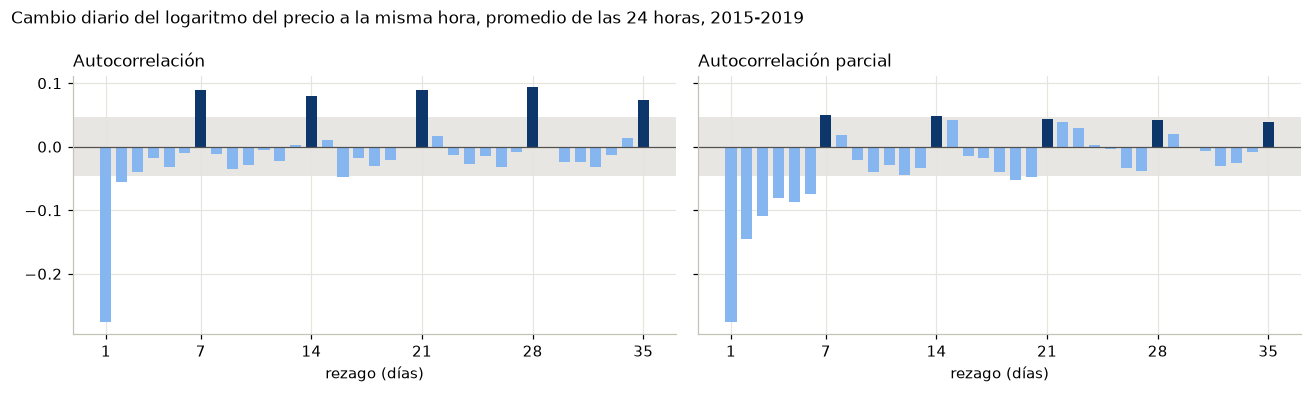

autocorrelación en los rezagos 1, 7, 14, 21 y 28: [-0.276  0.09   0.08   0.089  0.093]


In [11]:
cambio = LP.loc[:"2019-12-31"].diff().dropna()
REZAGOS = 35
fac = np.array([acf(cambio[h], nlags=REZAGOS) for h in cambio.columns]).mean(axis=0)
facp = np.array([pacf(cambio[h], nlags=REZAGOS) for h in cambio.columns]).mean(axis=0)
banda = 1.96 / np.sqrt(len(cambio))
k = np.arange(1, REZAGOS + 1)
colores = [AZUL_OSCURO if r % 7 == 0 else AZUL_CLARO for r in k]

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, valores, titulo in zip(ejes, [fac, facp], ["Autocorrelación", "Autocorrelación parcial"]):
    ax.axhspan(-banda, banda, color=GRIS_CLARO, alpha=0.4, lw=0, zorder=0)
    ax.bar(k, valores[1:], color=colores, width=0.7, zorder=2)
    ax.axhline(0, color=GRIS, lw=0.8)
    ax.set_xticks([1, 7, 14, 21, 28, 35])
    ax.set_xlabel("rezago (días)")
    ax.set_title(titulo)
fig.suptitle("Cambio diario del logaritmo del precio a la misma hora, promedio de las 24 horas, 2015-2019",
             x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()
print("autocorrelación en los rezagos 1, 7, 14, 21 y 28:", fac[[1, 7, 14, 21, 28]].round(3))

El rezago 1 es negativo: un salto del precio tiende a devolverse al día siguiente. Los rezagos 7,
14, 21 y 28 son positivos: el precio de un día se parece al del mismo día de las semanas
anteriores. Por eso SARIMAX tiene estacionalidad de 7 días, y entre las columnas del precio que se
le ofrecen a XGBoost están los rezagos de 7, 14, 21 y 28 días.

## 5. Lo que se pronostica: el cambio a una semana (2015-2022)

El objetivo es $y_h = \ln P(t+h,\,H) - \ln P(t,\,H)$, para $h = 3$ a $9$. Su tamaño dice qué tan
difícil es el pronóstico. El ingenuo del día pronostica $y_h = 0$, así que su RMSE es el de $y_h$;
el ingenuo semanal repite el precio del mismo día de la semana en la última semana conocida. Se
usan las filas cuyo día pronosticado cae entre 2015 y 2022, sin mirar 2023.

$y_h$ se puede partir en dos: el cambio del nivel del día, que es el promedio de sus 24 horas, y el
cambio de la forma del día, que es lo que queda. La última columna dice qué parte del cuadrado medio
de $y_h$ es del nivel.

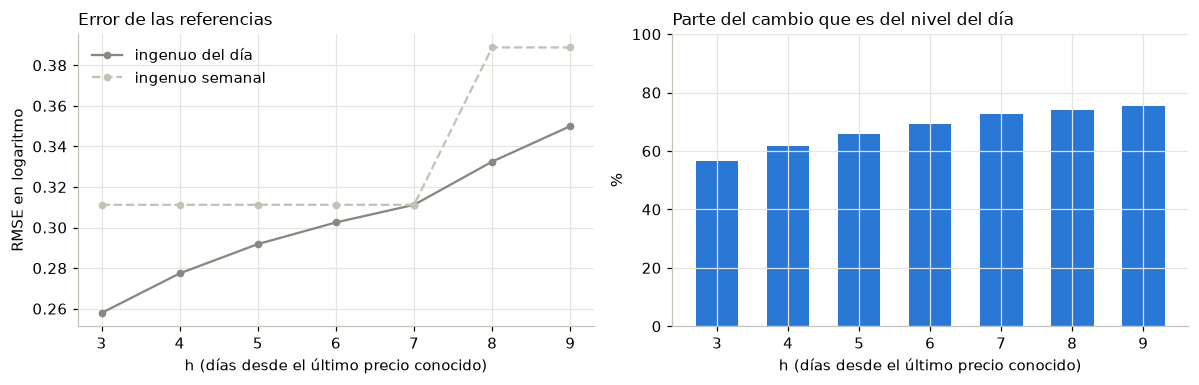

,RMSE ingenuo del día,RMSE ingenuo semanal,parte del nivel del día (%)
h,,,
3,0.258,0.311,56.472
4,0.277,0.311,61.677
5,0.292,0.311,65.769
6,0.303,0.311,69.264
7,0.311,0.311,72.776
8,0.332,0.389,74.085
9,0.350,0.389,75.299


In [12]:
filas = []
for h in range(3, 10):
    y = LP.shift(-h) - LP
    semanas = 1 if h <= 7 else 2
    # el ingenuo semanal toma el día t + h - 7 (o t + h - 14 si ese día todavía no se conoce)
    error_semanal = LP.shift(-h) - LP.shift(7 * semanas - h)
    dentro = (LP.index + pd.Timedelta(days=h) <= "2022-12-31") & error_semanal.notna().all(axis=1)
    y, error_semanal = y[dentro], error_semanal[dentro]
    nivel_dia = y.mean(axis=1)
    filas.append({"h": h, "RMSE ingenuo del día": np.sqrt((y ** 2).mean(axis=1).mean()),
                  "RMSE ingenuo semanal": np.sqrt((error_semanal ** 2).mean(axis=1).mean()),
                  "parte del nivel del día (%)": 100 * (nivel_dia ** 2).mean() / (y ** 2).mean(axis=1).mean()})
objetivo = pd.DataFrame(filas).set_index("h")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.plot(objetivo.index, objetivo["RMSE ingenuo del día"], color=GRIS_MEDIO, marker="o", ms=4, label="ingenuo del día")
a1.plot(objetivo.index, objetivo["RMSE ingenuo semanal"], color=GRIS_CLARO, marker="o", ms=4, ls="--", label="ingenuo semanal")
a1.set_ylabel("RMSE en logaritmo")
a1.set_title("Error de las referencias")
a1.legend()
a2.bar(objetivo.index, objetivo["parte del nivel del día (%)"], color=AZUL, width=0.6)
a2.set_ylim(0, 100)
a2.set_ylabel("%")
a2.set_title("Parte del cambio que es del nivel del día")
for ax in (a1, a2):
    ax.set_xticks(range(3, 10))
    ax.set_xlabel("h (días desde el último precio conocido)")
plt.tight_layout()
plt.show()
objetivo.round(3)

A tres días el ingenuo del día tiene un RMSE de 0,26 en logaritmo y a nueve días, de 0,35. El
semanal es peor en todos los horizontes, salvo en $h = 7$, donde los dos pronostican lo mismo: el
precio del día $t$. Por eso la referencia principal de la tesis es el ingenuo del día.

La mayor parte del cambio es del nivel del día: 56% del cuadrado medio en $h = 3$ y 75% en
$h = 9$. Lo difícil a una semana es anticipar si el día entero va a estar más caro o más barato, más
que la forma del día. Por eso importan las variables que mueven el nivel, como el agua y el
despacho.

## 6. El agua y El Niño

Los aportes son el agua que llega a los embalses, y XM los publica también como porcentaje de su
media histórica. Primero, el ciclo normal del año, con la media histórica de los aportes y el
volumen útil de los embalses:

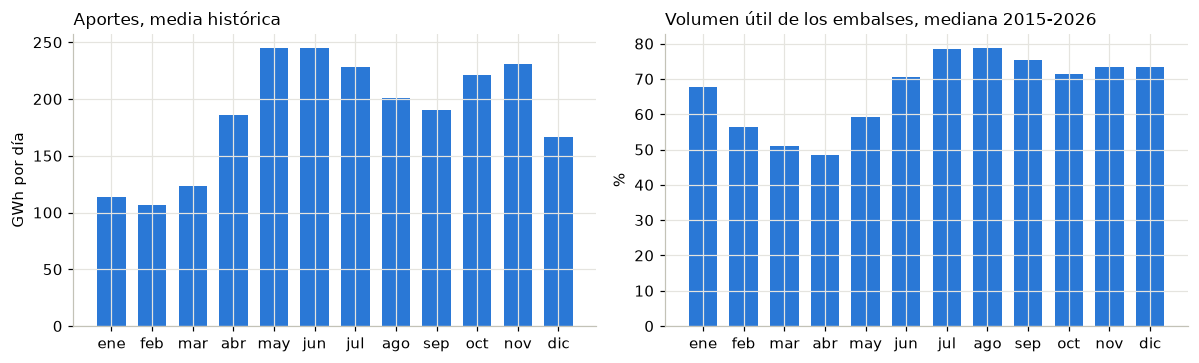

In [13]:
mes = diario.index.month
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4))
a1.bar(range(12), diario["aportes_media_hist"].groupby(mes).mean() / 1e6, color=AZUL, width=0.7)
a1.set_ylabel("GWh por día")
a1.set_title("Aportes, media histórica")
a2.bar(range(12), 100 * diario["volumen_util_pct"].groupby(mes).median(), color=AZUL, width=0.7)
a2.set_ylabel("%")
a2.set_title("Volumen útil de los embalses, mediana 2015-2026")
for ax in (a1, a2):
    ax.set_xticks(range(12), MESES)
plt.tight_layout()
plt.show()

Los aportes son bajos de enero a marzo y altos de mayo a julio y en octubre y noviembre; los
embalses llegan a su mínimo en marzo y abril. Es el ciclo del precio de la sección 3, al revés.

Para ver cómo se relacionan el precio y el agua más allá del ciclo del año se usan promedios
mensuales de 2015 a 2022 y la correlación de Spearman, que no la mueven los picos. La tabla da la
correlación con el logaritmo del precio del mismo mes:

In [14]:
NOMBRES = {"aportes_pct_sistema": "aportes (% de la media histórica)", "volumen_util_pct": "volumen útil",
           "lluvia_anom_acum90": "anomalía de lluvia de 90 días", "oni": "ONI",
           "nino34_anom": "Niño 3.4 semanal", "nino12_anom": "Niño 1+2 semanal"}
mensual = diario[list(NOMBRES)].assign(lp=lp_dia).resample("MS").mean().loc[:"2022-12"]
(mensual.corr(method="spearman")["lp"].drop("lp").rename(NOMBRES)
 .rename_axis("variable").to_frame("Spearman con el precio").round(2))

,Spearman con el precio
variable,
aportes (% de la media histórica),-0.55
volumen útil,-0.46
anomalía de lluvia de 90 días,-0.36
ONI,0.34
Niño 3.4 semanal,0.26
Niño 1+2 semanal,0.24


Los aportes y los embalses van en contra del precio: con más agua, precio más bajo. Pero lo que
sirve para pronosticar es la relación con el pasado. La figura repite la correlación con el valor
de cada variable $k$ meses antes:

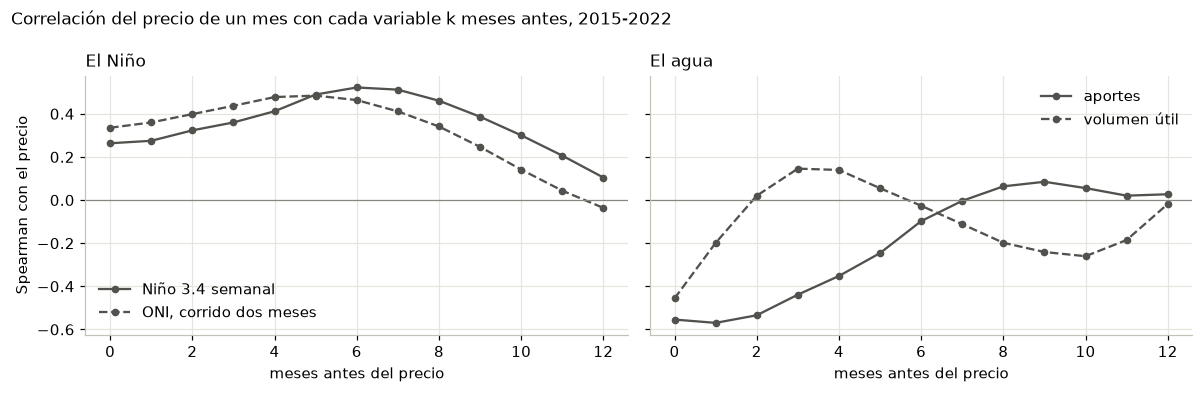

,Niño 3.4 semanal,ONI,aportes (% de la media histórica),volumen útil
meses antes,,,,
0,0.26,0.34,-0.55,-0.46
1,0.27,0.36,-0.57,-0.20
3,0.36,0.44,-0.44,0.15
6,0.52,0.46,-0.10,-0.03
9,0.39,0.25,0.08,-0.24
12,0.10,-0.04,0.03,-0.02


In [15]:
adelanto = pd.DataFrame({NOMBRES[c]: [mensual["lp"].corr(mensual[c].shift(k), method="spearman") for k in range(13)]
                         for c in ["nino34_anom", "oni", "aportes_pct_sistema", "volumen_util_pct"]})
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
a1.plot(adelanto.index, adelanto["Niño 3.4 semanal"], color=GRIS, marker="o", ms=4, label="Niño 3.4 semanal")
a1.plot(adelanto.index, adelanto["ONI"], color=GRIS, marker="o", ms=4, ls="--", label="ONI, corrido dos meses")
a1.set_title("El Niño")
a2.plot(adelanto.index, adelanto["aportes (% de la media histórica)"], color=GRIS, marker="o", ms=4, label="aportes")
a2.plot(adelanto.index, adelanto["volumen útil"], color=GRIS, marker="o", ms=4, ls="--", label="volumen útil")
a2.set_title("El agua")
for ax in (a1, a2):
    ax.axhline(0, color=GRIS_MEDIO, lw=0.8)
    ax.set_xticks(range(0, 13, 2))
    ax.set_xlabel("meses antes del precio")
    ax.legend()
a1.set_ylabel("Spearman con el precio")
fig.suptitle("Correlación del precio de un mes con cada variable k meses antes, 2015-2022", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()
adelanto.loc[[0, 1, 3, 6, 9, 12]].round(2).rename_axis("meses antes")

La relación con los aportes es más fuerte en el mismo mes y en el anterior ($-0{,}57$) y se pierde
hacia los seis meses. La de Niño 3.4 crece con la distancia: es de 0,26 en el mismo mes y de 0,52
seis meses antes. El calentamiento del Pacífico se adelanta al precio cerca de medio año. El ONI,
que ya va corrido dos meses por su publicación, llega a su máximo cuatro o cinco meses antes.

El ONI es un promedio de tres meses y se conoce dos meses después, así que llega tarde. NOAA publica
cada semana la temperatura de las regiones Niño, y por eso el panel trae esas series. En 2026 se
vio la diferencia:

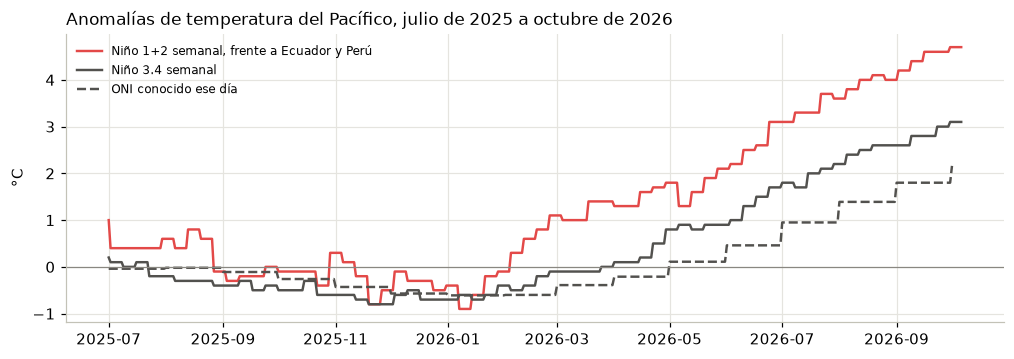

,oni,nino34_anom,nino12_anom,precio_bolsa
ene,-0.61,-0.62,-0.47,212.39
feb,-0.60,-0.33,0.57,124.42
mar,-0.39,-0.08,1.19,220.20
abr,-0.21,0.26,1.50,269.01
may,0.11,0.86,1.71,504.99
jun,0.46,1.34,2.57,546.31


In [16]:
reciente = diario.loc["2025-07-01":, ["oni", "nino34_anom", "nino12_anom"]]
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(reciente.index, reciente["nino12_anom"], color=ROJO, lw=1.6, label="Niño 1+2 semanal, frente a Ecuador y Perú")
ax.plot(reciente.index, reciente["nino34_anom"], color=GRIS, lw=1.6, label="Niño 3.4 semanal")
ax.plot(reciente.index, reciente["oni"], color=GRIS, lw=1.6, ls="--", label="ONI conocido ese día")
ax.axhline(0, color=GRIS_MEDIO, lw=0.8)
ax.set_ylabel("°C")
ax.set_title("Anomalías de temperatura del Pacífico, julio de 2025 a octubre de 2026")
ax.legend(fontsize=8)
plt.show()

(diario.loc["2026-01-01":"2026-06-30", ["oni", "nino34_anom", "nino12_anom", "precio_bolsa"]]
 .resample("MS").mean().set_axis(MESES[:6]).round(2))

En febrero y marzo de 2026 el ONI que se conocía todavía era negativo, del lado de La Niña
($-0{,}6$ y $-0{,}4$), mientras Niño 1+2 ya estaba 0,6 y 1,2 °C por encima de lo normal. El ONI
pasó a positivo en mayo, el mismo mes en que el precio promedio subió de 269 a 505 COP/kWh.

## 7. El precio de escasez

La regulación define un precio de escasez dentro del cargo por confiabilidad. Cuando el precio de
bolsa lo supera, se activan las obligaciones de energía firme, con las que los generadores se
comprometen a entregar energía en condiciones críticas (CREG 071 de 2006). Desde diciembre de 2017
XM publica además el precio de escasez de activación.

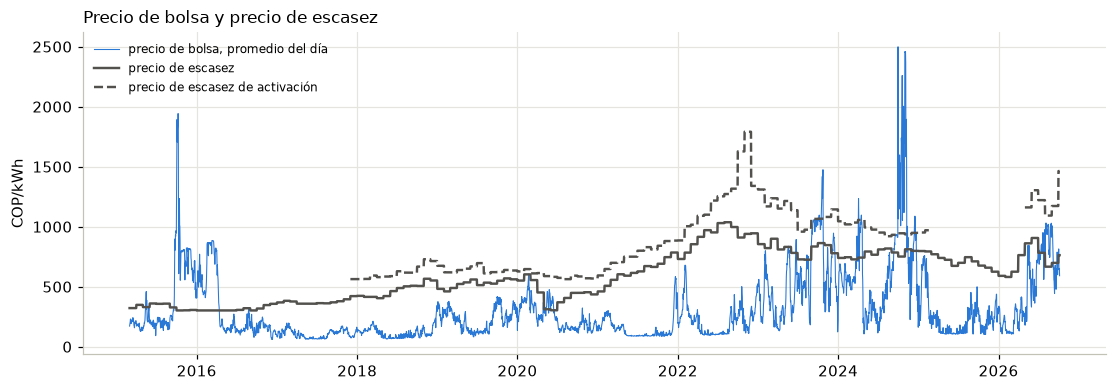

horas con el precio por encima del precio de escasez: 11.9%


año,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
% de las horas,35.0,28.4,0.0,0.0,0.0,9.3,0.0,0.1,23.4,28.1,2.6,21.2


In [17]:
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(precio_dia.index, precio_dia, color=AZUL, lw=0.7, label="precio de bolsa, promedio del día")
ax.plot(diario.index, diario["precio_escasez"], color=GRIS, lw=1.6, label="precio de escasez")
ax.plot(diario.index, diario["precio_esca_act"], color=GRIS, lw=1.6, ls="--", label="precio de escasez de activación")
ax.set_ylabel("COP/kWh")
ax.set_title("Precio de bolsa y precio de escasez")
ax.legend(loc="upper left", fontsize=8)
plt.show()

escasez = horario["fecha"].map(diario["precio_escasez"])
encima = 100 * (horario["precio"] > escasez)
print(f"horas con el precio por encima del precio de escasez: {encima.mean():.1f}%")
encima.groupby(anio).mean().round(1).rename_axis("año").to_frame("% de las horas").T

El precio supera el precio de escasez en 12% de las horas, casi todas en 2015-2016, 2020, 2023-2024
y 2026. La distancia entre los dos, en logaritmo, es la variable `brecha_escasez`, que está en el
bloque hidrológico de la LSTM. Se calcula con el precio de escasez porque el de activación no tiene
datos entre marzo de 2025 y abril de 2026 (`docs/PANEL_HORARIO.md` del repositorio). Cuando el
precio llega al precio de escasez de activación se queda pegado a ese valor durante días (sección 7
de `4_comparacion.ipynb`).

## 8. El despacho programado

XM publica la víspera el despacho programado de cada día, con su costo marginal por hora. No es el
precio de bolsa, que sale del despacho ideal y se calcula después del día (CREG 055 de 1994), pero
se le parece mucho. En el panel de la LSTM, la fila del día $t$ trae el costo marginal del día
$R = t + 2$; aquí se compara con el precio de ese mismo día y hora.

correlación en logaritmo: 0.948
el precio queda por encima del costo marginal programado en 8.7%, en la mediana


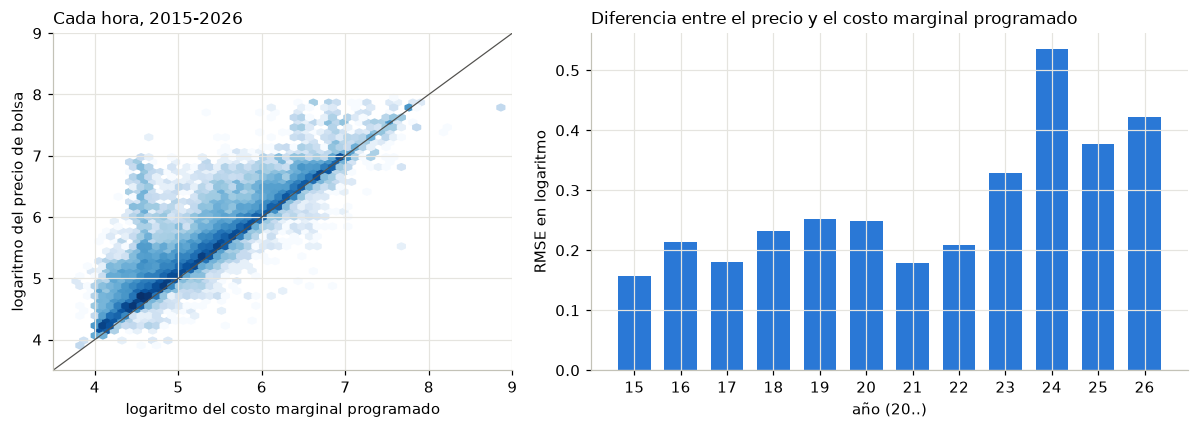

In [18]:
lstm = pd.read_csv(PANELES / "panel_lstm_bloques.csv.gz", parse_dates=["fecha"],
                   usecols=["fecha", "hora", "lp", "y_h3", "cmg_despacho", "cmg_hoy_vs_precio", "disp_decl_hoy_rel",
                            "frac_termica_prog", "aportes_media_hist", "volumen_util_pct", "brecha_escasez",
                            "presion_hidro_horaria", "dias_autonomia"])
lstm = lstm[(lstm["fecha"] >= "2015-03-01") & lstm["lp"].notna()]

cmg = lstm[["fecha", "hora", "cmg_despacho"]].assign(fecha=lstm["fecha"] + pd.Timedelta(days=2))
par = cmg.merge(lstm[["fecha", "hora", "lp"]], on=["fecha", "hora"])
diferencia = par["lp"] - par["cmg_despacho"]
rmse_anual = np.sqrt((diferencia ** 2).groupby(par["fecha"].dt.year).mean())
print(f"correlación en logaritmo: {par['lp'].corr(par['cmg_despacho']):.3f}")
print(f"el precio queda por encima del costo marginal programado en {pct(diferencia.median()):.1f}%, en la mediana")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.3]})
# una sola hora tiene costo marginal de 1 COP/kWh o menos, que en logaritmo queda en 0, y no se ve aquí
lim = [3.5, 9]
a1.hexbin(par["cmg_despacho"], par["lp"], gridsize=60, extent=lim + lim, cmap="Blues", mincnt=1, bins="log")
a1.plot(lim, lim, color=GRIS, lw=0.8)
a1.set_xlim(lim)
a1.set_ylim(lim)
a1.set_xlabel("logaritmo del costo marginal programado")
a1.set_ylabel("logaritmo del precio de bolsa")
a1.set_title("Cada hora, 2015-2026")
a2.bar(rmse_anual.index, rmse_anual, color=AZUL, width=0.7)
a2.set_xticks(rmse_anual.index, [str(a)[2:] for a in rmse_anual.index])
a2.set_xlabel("año (20..)")
a2.set_ylabel("RMSE en logaritmo")
a2.set_title("Diferencia entre el precio y el costo marginal programado")
plt.tight_layout()
plt.show()

La correlación en logaritmo es de 0,95, y en la mediana el precio queda 9% por encima del costo
marginal programado. Pero la diferencia es mayor desde 2023: el RMSE en logaritmo está entre 0,16 y
0,25 de 2015 a 2022, y entre 0,33 y 0,54 desde 2023. El despacho programado es una buena guía del nivel del día, pero no es un
pronóstico del precio.

Lo que sí sirve es comparar el despacho del día $R$ con el último precio conocido, que es la
variable `cmg_hoy_vs_precio`. La tabla da la correlación de Spearman de las nueve variables que usa
la LSTM con el cambio a tres días, $y_3$, en las filas cuyo día pronosticado cae entre 2015 y 2022:

In [19]:
BLOQUE = {"cmg_hoy_vs_precio": "despacho de hoy", "cmg_despacho": "despacho de hoy",
          "disp_decl_hoy_rel": "despacho de hoy", "frac_termica_prog": "despacho de hoy",
          "brecha_escasez": "estado hidrológico", "presion_hidro_horaria": "estado hidrológico",
          "volumen_util_pct": "estado hidrológico", "aportes_media_hist": "estado hidrológico",
          "dias_autonomia": "estado hidrológico"}
hasta_2022 = lstm[(lstm["fecha"] + pd.Timedelta(days=3) <= "2022-12-31") & lstm["y_h3"].notna()]
(pd.DataFrame({"bloque": BLOQUE,
               "Spearman con y_3": hasta_2022[list(BLOQUE)].corrwith(hasta_2022["y_h3"], method="spearman")})
 .rename_axis("variable").round(3))

,bloque,Spearman con y_3
variable,,
cmg_hoy_vs_precio,despacho de hoy,0.602
cmg_despacho,despacho de hoy,0.057
disp_decl_hoy_rel,despacho de hoy,-0.047
frac_termica_prog,despacho de hoy,-0.028
brecha_escasez,estado hidrológico,-0.176
presion_hidro_horaria,estado hidrológico,0.108
volumen_util_pct,estado hidrológico,0.079
aportes_media_hist,estado hidrológico,-0.014
dias_autonomia,estado hidrológico,0.065


`cmg_hoy_vs_precio` tiene una correlación de 0,60 con el cambio a tres días, y ninguna variable del
estado hidrológico pasa de 0,2 en valor absoluto. El despacho del día $R$ ya muestra buena parte del
cambio de nivel entre el día $t$ y el día $R$, y $h = 3$ es el día siguiente a $R$. Es lo que más le
aporta a la LSTM (`3_lstm.ipynb`). Las variables hidrológicas, en cambio, se mueven despacio: dicen
poco del cambio de un día a otro, pero sí del nivel en las semanas y meses siguientes.

## 9. Qué grupos de variables traen información (2015-2019)

Para la LSTM se midió cuánto aporta cada grupo de variables por separado: se agrega al precio y al
calendario en un XGBoost de prueba, que se entrena hasta 2017 y se mide en 2018, y se entrena hasta
2018 y se mide en 2019, en $h = 3$, $6$ y $9$ (paso 2f del repositorio,
`paneles/panel_lstm_grupos.csv`). La figura muestra el cambio del RMSE en logaritmo frente a usar
solo el precio y el calendario. Un valor negativo quiere decir que el grupo ayuda.

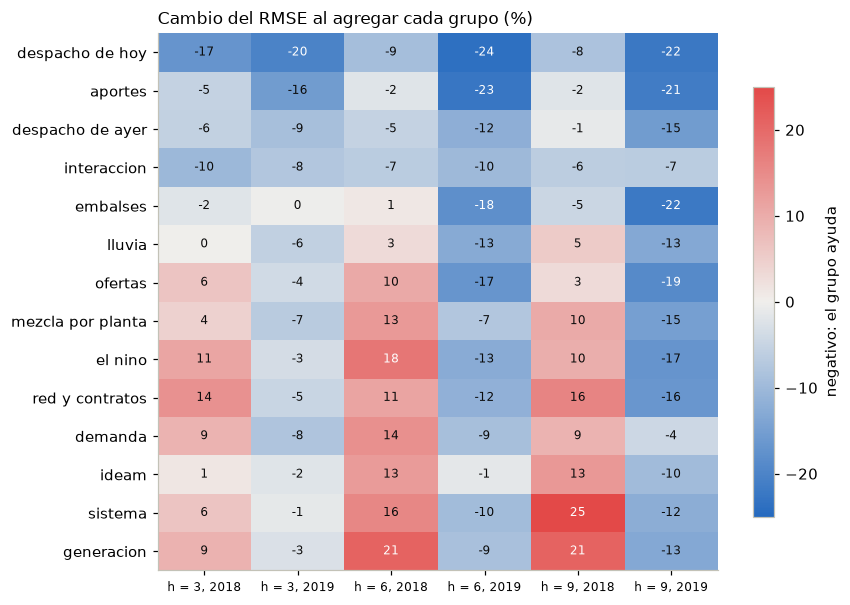

In [20]:
grupos = pd.read_csv(PANELES / "panel_lstm_grupos.csv")
mapa = grupos.pivot_table(index="grupo", columns=["h", "año"], values="cambio_rmse")
mapa = mapa.loc[mapa.mean(axis=1).sort_values().index]
mapa.index = mapa.index.str.replace("_", " ")

divergente = LinearSegmentedColormap.from_list("divergente", ["#256abf", "#f0efec", ROJO])
fig, ax = plt.subplots(figsize=(8, 5.6))
im = ax.imshow(mapa.to_numpy(), cmap=divergente, vmin=-25, vmax=25, aspect="auto")
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        v = mapa.iat[i, j]
        texto = f"{v:.0f}" if round(v) != 0 else "0"
        ax.text(j, i, texto, ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 17 else "#0b0b0b")
ax.set_xticks(range(mapa.shape[1]), [f"h = {h}, {a}" for h, a in mapa.columns], fontsize=8)
ax.set_yticks(range(mapa.shape[0]), mapa.index)
ax.grid(False)
ax.set_title("Cambio del RMSE al agregar cada grupo (%)")
fig.colorbar(im, ax=ax, shrink=0.8, label="negativo: el grupo ayuda")
plt.tight_layout()
plt.show()

Solo cuatro grupos ayudan en los dos años y en los tres horizontes: el despacho de hoy, que baja el
error entre 8% y 24%, los aportes, el despacho de ayer y el grupo `interaccion`, que tiene la
escasez y la presión hídrica. Los embalses fallan en una de las seis combinaciones. Los demás grupos,
como la demanda, la generación, las ofertas, los contratos y El Niño, empeoran el error en 2018, o
casi no lo cambian, y solo ayudan en 2019. Más variables no es mejor: con esto se armaron los bloques de la LSTM.

La selección de XGBoost (paso 2d) da otra mirada: la importancia SHAP de cada grupo, en porcentaje
del total, para horizontes de 1 a 30 días.

In [21]:
importancia = pd.read_csv(PANELES / "panel_horario_modelo_variables.csv")
H = [1, 3, 5, 7, 14, 30]
por_grupo = importancia.groupby("grupo")[[f"importancia_pct_h{h}" for h in H]].sum()
por_grupo.columns = [f"h = {h}" for h in H]
por_grupo.index = por_grupo.index.str.replace("_", " ")
por_grupo.sort_values("h = 3", ascending=False).round(1)

,h = 1,h = 3,h = 5,h = 7,h = 14,h = 30
grupo,,,,,,
precio,19.1,19.5,18.1,16.2,13.5,15.6
generacion,8.5,8.4,9.1,7.9,5.2,5.0
curva de merito,4.1,7.9,5.1,4.4,4.2,3.9
lluvia,3.9,7.7,8.5,9.9,11.5,11.9
mezcla por planta,5.4,7.4,8.3,10.1,10.1,7.4
embalses,2.2,6.6,6.6,6.3,7.6,11.6
interaccion,7.0,6.3,5.7,6.2,6.2,2.6
aportes,3.3,6.2,5.4,4.6,3.9,6.5
red y contratos,5.0,6.1,5.4,4.6,4.6,6.0


El precio es el grupo más importante en todos los horizontes. El costo marginal pesa 17% a un día y
entre 1% y 3% desde tres días. Con el horizonte crece el agua: la lluvia pasa de 4% en $h = 1$ a 12%
en $h = 30$, los embalses de 2% a 12% y El Niño de 1% a 5%. Cuanto más lejos el pronóstico, más pesan
la hidrología y el clima.

## 10. Resumen

1. El precio cambia de escala entre años, de 106 a 676 COP/kWh en promedio anual, y tiene picos de
   más de 2.600 COP/kWh. Los años caros coinciden con El Niño y con menos energía hidráulica.
2. En logaritmo el precio es casi simétrico y sus cambios tienen el mismo tamaño en cualquier
   nivel. Por eso se modela el logaritmo y su cambio.
3. Tiene un ciclo diario (pico en la hora 20, el mismo de la demanda), uno semanal (domingos y
   festivos más baratos) y uno anual (caro de diciembre a marzo, barato de mayo a agosto).
4. El nivel no es estacionario y el cambio diario sí. El cambio tiene autocorrelación negativa en
   el rezago 1 y positiva en los múltiplos de 7.
5. A una semana, la mayor parte del cambio es del nivel del día (56% a 75%), y el ingenuo del día
   es mejor referencia que el semanal.
6. Los aportes se relacionan con el precio del mismo mes y del siguiente; El Niño se adelanta cerca
   de seis meses, y sus series semanales dan la señal antes que el ONI.
7. El despacho programado del día del pronóstico es la variable más relacionada con el cambio a
   tres días. Las hidrológicas pesan más a medida que el horizonte se alarga.

## Referencias

- Dickey, D. y Fuller, W. (1979). Distribution of the estimators for autoregressive time series
  with a unit root. *Journal of the American Statistical Association*, 74(366), 427-431.
- Galli, S. *Feature Engineering for Machine Learning*. Repositorio
  github.com/solegalli/feature-engineering-for-machine-learning. Sección 11.
- Hyndman, R. y Athanasopoulos, G. (2021). *Forecasting: Principles and Practice*, tercera edición. OTexts.
- Kwiatkowski, D., Phillips, P., Schmidt, P. y Shin, Y. (1992). Testing the null hypothesis of
  stationarity against the alternative of a unit root. *Journal of Econometrics*, 54(1-3), 159-178.
- NOAA, Climate Prediction Center. Índices semanales de temperatura del Pacífico en las regiones
  Niño y Oceanic Niño Index (ONI).
- Resolución CREG 055 de 1994, art. 14 (precio horario de la bolsa de energía).
- Resolución CREG 071 de 2006. Metodología del Cargo por Confiabilidad.
- Uniejewski, B., Weron, R. y Ziel, F. (2018). Variance stabilizing transformations for electricity
  spot price forecasting. *IEEE Transactions on Power Systems*, 33(2), 2219-2229.
- Weron, R. (2014). Electricity price forecasting: A review of the state-of-the-art with a look into
  the future. *International Journal of Forecasting*, 30(4), 1030-1081.